# 03 · Feature Engineering: una fila por cliente

**¿Qué variables vamos a utilizar para representar a cada cliente?**

Los algoritmos de segmentación y de predicción de churn no trabajan con transacciones sino con **clientes**. En este notebook transformamos las ~780.000 líneas de pedido de la base de datos en una tabla con **una fila por cliente** y columnas que describen su comportamiento.

Las variables siguen el esquema del proyecto y se basan en el modelo **RFM**, el estándar en análisis de clientes:

| Variable | Qué representa | Por qué es útil |
|---|---|---|
| `recencia` | Días desde la última compra | El mejor indicador de si un cliente sigue "vivo" |
| `frecuencia` | Número de pedidos distintos | Mide la fidelidad / hábito de compra |
| `gasto` | Gasto **neto** total (£) = compras − cancelaciones | Mide el valor económico del cliente |
| `ticket_medio` | Gasto medio por pedido | Distingue clientes de pedidos grandes y pequeños |
| `productos_distintos` | Nº de productos diferentes comprados | Amplitud de la relación con el catálogo |
| `unidades` | Nº total de artículos comprados | Volumen (perfil mayorista vs minorista) |
| `antiguedad_dias` | Días desde la primera compra | Cuánto tiempo hace que nos conoce |
| `vida_cliente_dias` | Días entre primera y última compra | Duración de su relación activa (*customer lifetime*) |
| `frecuencia_mensual` | Pedidos por mes desde su primera compra | Ritmo de compra, comparable entre clientes nuevos y antiguos |
| `dias_entre_compras` | Media de días entre compras consecutivas | Ciclo natural de compra |
| `tasa_cancelacion` | % del gasto bruto que se canceló | Posible señal de insatisfacción |
| `pais` / `es_reino_unido` | País del cliente | Contexto geográfico |

### 0. Librerías

In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Estilo común de los gráficos: ejes y rejilla discretos para que destaquen los datos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "font.size": 10,
})
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#b5b4ad"

### 1. Conexión a la base de datos
Trabajamos sobre la base de datos limpia creada en `02_limpieza_datos`, así que ya no necesitamos volver a leer el Excel.

In [2]:
RUTA_DB = Path("../data/processed/online_retail.db")
RUTA_FEATURES = Path("../data/processed/features_clientes.csv")

con = sqlite3.connect(RUTA_DB)

def sql(consulta):
    return pd.read_sql_query(consulta, con)

sql("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,customers
1,products
2,orders
3,order_details


### 2. Agregación por cliente con SQL
Hacemos la agregación principal directamente en SQL, igual que se haría en un *data warehouse*. Usamos **CTEs** (`WITH ...`) para que la consulta se lea por bloques:

1. `lineas`: une pedidos y líneas de pedido y calcula el importe de cada línea.
2. `compras`: métricas de las **ventas** de cada cliente.
3. `cancelaciones`: importe y número de pedidos **cancelados** de cada cliente.
4. Consulta final: une todo con la tabla de clientes. Usamos `LEFT JOIN` con las cancelaciones porque la mayoría de clientes no ha cancelado nunca.

In [3]:
consulta_clientes = """
WITH lineas AS (
    SELECT o.customer_id, o.order_id, o.order_date, o.is_cancellation,
           d.product_id, d.quantity,
           d.quantity * d.unit_price AS importe
    FROM orders o
    JOIN order_details d ON d.order_id = o.order_id
),
compras AS (
    SELECT customer_id,
           COUNT(DISTINCT order_id)   AS frecuencia,
           MIN(order_date)            AS primera_compra,
           MAX(order_date)            AS ultima_compra,
           SUM(importe)               AS gasto_bruto,
           SUM(quantity)              AS unidades,
           COUNT(DISTINCT product_id) AS productos_distintos
    FROM lineas
    WHERE is_cancellation = 0
    GROUP BY customer_id
),
cancelaciones AS (
    SELECT customer_id,
           COUNT(DISTINCT order_id) AS pedidos_cancelados,
           -SUM(importe)            AS gasto_cancelado
    FROM lineas
    WHERE is_cancellation = 1
    GROUP BY customer_id
)
SELECT c.customer_id,
       c.country                                 AS pais,
       co.frecuencia,
       co.primera_compra,
       co.ultima_compra,
       co.gasto_bruto,
       COALESCE(ca.gasto_cancelado, 0)           AS gasto_cancelado,
       COALESCE(ca.pedidos_cancelados, 0)        AS pedidos_cancelados,
       co.unidades,
       co.productos_distintos
FROM compras co
JOIN customers c          ON c.customer_id = co.customer_id
LEFT JOIN cancelaciones ca ON ca.customer_id = co.customer_id
"""

clientes = sql(consulta_clientes)
# Nos quedamos solo con el día (sin la hora): la recencia se mide en días naturales
clientes["primera_compra"] = pd.to_datetime(clientes["primera_compra"]).dt.normalize()
clientes["ultima_compra"] = pd.to_datetime(clientes["ultima_compra"]).dt.normalize()
clientes = clientes.set_index("customer_id")

print(f"Clientes con al menos una compra: {len(clientes):,}")
clientes.head()

Clientes con al menos una compra: 5,852


,pais,frecuencia,primera_compra,ultima_compra,gasto_bruto,gasto_cancelado,pedidos_cancelados,unidades,productos_distintos
customer_id,,,,,,,,,
12346,United Kingdom,3,2010-03-02,2011-01-18,77352.96,77183.60,1,74239,25
12347,Iceland,8,2010-10-31,2011-12-07,4921.53,0.00,0,2967,126
12348,Finland,5,2010-09-27,2011-09-25,1658.40,0.00,0,2704,24
12349,Italy,3,2010-04-29,2011-11-21,3678.69,24.15,1,1621,137
12350,Norway,1,2011-02-02,2011-02-02,294.40,0.00,0,196,16


### 3. Fecha de referencia
Para calcular la recencia necesitamos un "hoy". Como el dataset es histórico, usamos como fecha de referencia **el día siguiente a la última transacción registrada**. Simula que hacemos el análisis justo al día siguiente de cerrar los datos. Sumar un día es la convención habitual en RFM: así un cliente que compró el último día tiene recencia 1 y no 0.

In [4]:
fecha_referencia = clientes["ultima_compra"].max() + pd.Timedelta(days=1)
print(f"Primera transacción: {clientes['primera_compra'].min():%Y-%m-%d}")
print(f"Última transacción:  {clientes['ultima_compra'].max():%Y-%m-%d}")
print(f"Fecha de referencia: {fecha_referencia:%Y-%m-%d}")

Primera transacción: 2009-12-01
Última transacción:  2011-12-09
Fecha de referencia: 2011-12-10


### 4. Construcción de las variables

#### 4.1 RFM y gasto neto
**¿Por qué gasto neto y no bruto?** Porque las cancelaciones devuelven el dinero. Si usamos el gasto bruto, un cliente que compra 1.000 £ y devuelve 1.000 £ parecería tan valioso como uno que compra 1.000 £ y se lo queda.

In [5]:
features = pd.DataFrame(index=clientes.index)
features["pais"] = clientes["pais"]

features["recencia"] = (fecha_referencia - clientes["ultima_compra"]).dt.days
features["frecuencia"] = clientes["frecuencia"]
features["gasto_bruto"] = clientes["gasto_bruto"]
features["gasto_cancelado"] = clientes["gasto_cancelado"]
features["gasto"] = clientes["gasto_bruto"] - clientes["gasto_cancelado"]

features[["recencia", "frecuencia", "gasto_bruto", "gasto_cancelado", "gasto"]].describe().round(1)

,recencia,frecuencia,gasto_bruto,gasto_cancelado,gasto
count,5852.0,5852.0,5852.0,5852.0,5852.0
mean,200.7,6.3,2916.7,121.1,2795.6
std,208.5,12.7,14306.9,2503.0,13825.3
min,1.0,1.0,3.0,0.0,-1343.2
25%,26.0,1.0,339.6,0.0,330.9
50%,96.0,3.0,856.0,0.0,840.2
75%,380.0,7.0,2241.0,27.4,2172.0
max,739.0,373.0,580987.0,168469.6,578408.6


Aparecen clientes con **gasto neto negativo o nulo**. ¿Quiénes son? Ordenamos por importe cancelado:

In [6]:
features.sort_values("gasto_cancelado", ascending=False).head(6)[
    ["frecuencia", "gasto_bruto", "gasto_cancelado", "gasto"]
]

,frecuencia,gasto_bruto,gasto_cancelado,gasto
customer_id,,,,
16446,2,168472.50,168469.60,2.90
12346,3,77352.96,77183.60,169.36
15749,3,44534.30,22998.40,21535.90
12931,57,92347.34,20800.37,71546.97
14911,373,272252.79,13730.36,258522.43
14277,8,16789.16,12829.34,3959.82


Este es el motivo por el que usamos gasto neto: el cliente **16446** tendría un gasto bruto de **168.000 £** (sería de los mejores clientes de la empresa), pero canceló prácticamente todo; su valor real es de menos de 3 £. Lo mismo ocurre con el **12346**, que con gasto bruto aparecería entre los clientes más valiosos.

Los clientes con **gasto neto ≤ 0** han devuelto todo lo que compraron (o devuelven compras anteriores al periodo del dataset). No aportan valor económico y su gasto no se puede transformar con logaritmos, así que los **excluimos** del análisis:

In [7]:
sin_valor = features["gasto"] <= 0
print(f"Clientes con gasto neto <= 0: {sin_valor.sum()} ({sin_valor.mean():.2%})")

features = features[~sin_valor].copy()
clientes = clientes.loc[features.index]
print(f"Clientes en el análisis: {len(features):,}")

Clientes con gasto neto <= 0: 20 (0.34%)
Clientes en el análisis: 5,832


#### 4.2 Variables de comportamiento adicionales
- `ticket_medio`: gasto neto / nº de pedidos.
- `antiguedad_dias` y `vida_cliente_dias`: cuánto tiempo hace que nos conoce y cuánto duró su relación activa.
- `frecuencia_mensual`: pedidos por mes desde su primera compra. Usamos un mínimo de 1 mes en el denominador para que un cliente que compró ayer por primera vez no tenga una frecuencia "infinita".
- `tasa_cancelacion`: proporción del gasto bruto que acabó cancelado.

In [8]:
features["ticket_medio"] = features["gasto"] / features["frecuencia"]
features["productos_distintos"] = clientes["productos_distintos"]
features["unidades"] = clientes["unidades"]

features["antiguedad_dias"] = (fecha_referencia - clientes["primera_compra"]).dt.days
features["vida_cliente_dias"] = (clientes["ultima_compra"] - clientes["primera_compra"]).dt.days

meses_desde_primera_compra = (features["antiguedad_dias"] / 30.44).clip(lower=1)
features["frecuencia_mensual"] = features["frecuencia"] / meses_desde_primera_compra

features["tasa_cancelacion"] = (features["gasto_cancelado"] / features["gasto_bruto"]).clip(upper=1)
features["es_reino_unido"] = (features["pais"] == "United Kingdom").astype(int)

#### 4.3 Tiempo entre compras (con funciones ventana de SQL)
Para saber cada cuánto compra un cliente calculamos los días entre **cada compra y la anterior** del mismo cliente. En SQL esto se resuelve con la función ventana `LAG()`, que permite acceder a la fila anterior dentro de cada cliente (`PARTITION BY customer_id`) ordenada por fecha.

Trabajamos con **días de compra distintos**: si un cliente hace dos pedidos el mismo día, cuenta como una única visita (si no, aparecerían muchos intervalos de 0 días).

In [9]:
intervalos = sql("""
WITH dias_compra AS (
    SELECT DISTINCT customer_id, DATE(order_date) AS dia
    FROM orders
    WHERE is_cancellation = 0
)
SELECT customer_id,
       dia,
       JULIANDAY(dia) - JULIANDAY(LAG(dia) OVER (PARTITION BY customer_id ORDER BY dia)) AS dias_desde_anterior
FROM dias_compra
""").dropna()

intervalos = intervalos[intervalos["customer_id"].isin(features.index)]
intervalos["dias_desde_anterior"].describe(percentiles=[.25, .5, .75, .9]).round(1)

count    27025.0
mean        59.3
std         78.2
min          1.0
25%         13.0
50%         32.0
75%         70.0
90%        148.0
max        714.0
Name: dias_desde_anterior, dtype: float64

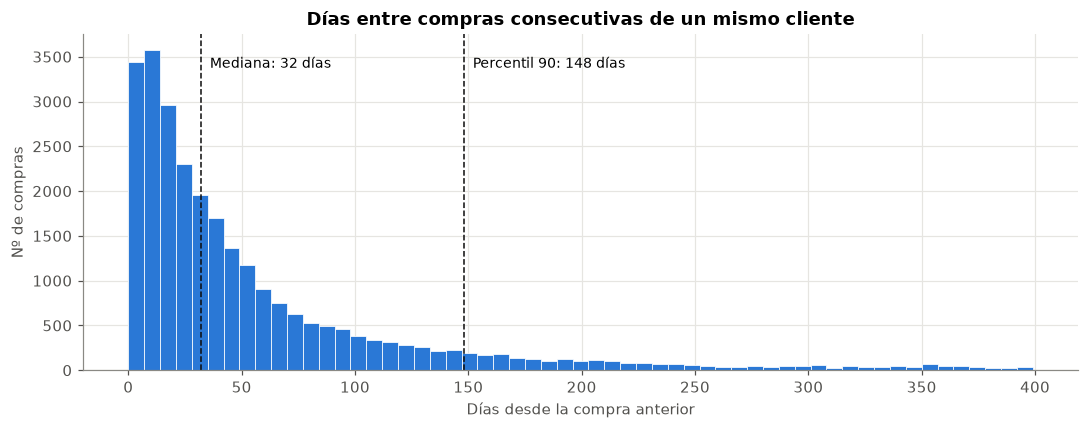

In [10]:
features["dias_entre_compras"] = intervalos.groupby("customer_id")["dias_desde_anterior"].mean()

mediana = intervalos["dias_desde_anterior"].median()
p90 = intervalos["dias_desde_anterior"].quantile(0.9)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(intervalos["dias_desde_anterior"], bins=range(0, 400, 7), color=AZUL, edgecolor="white", linewidth=0.5)
for valor, texto in [(mediana, f"Mediana: {mediana:.0f} días"), (p90, f"Percentil 90: {p90:.0f} días")]:
    ax.axvline(valor, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.text(valor + 4, ax.get_ylim()[1] * 0.9, texto, fontsize=9)
ax.set_title("Días entre compras consecutivas de un mismo cliente")
ax.set_xlabel("Días desde la compra anterior")
ax.set_ylabel("Nº de compras")
plt.tight_layout()
plt.show()

**Lectura:** la mitad de las veces un cliente vuelve a comprar en aproximadamente un mes, y en el 90 % de los casos vuelve antes de unos 5 meses (~150 días). Esto nos da una referencia muy útil para el negocio y para la futura definición de churn: **un cliente que lleva más de ~150 días sin comprar se sale del patrón habitual** y probablemente esté en riesgo de abandono.

### 5. Tabla final de features

In [11]:
orden_columnas = [
    "pais", "es_reino_unido",
    "recencia", "frecuencia", "gasto", "ticket_medio",
    "productos_distintos", "unidades",
    "antiguedad_dias", "vida_cliente_dias", "frecuencia_mensual", "dias_entre_compras",
    "gasto_bruto", "gasto_cancelado", "tasa_cancelacion",
]
features = features[orden_columnas]
print(features.shape)
features.head()

(5832, 15)


,pais,es_reino_unido,recencia,frecuencia,gasto,ticket_medio,productos_distintos,unidades,antiguedad_dias,vida_cliente_dias,frecuencia_mensual,dias_entre_compras,gasto_bruto,gasto_cancelado,tasa_cancelacion
customer_id,,,,,,,,,,,,,,,
12346,United Kingdom,1,326,3,169.36,56.453333,25,74239,648,322,0.140926,161.000000,77352.96,77183.60,0.997811
12347,Iceland,0,3,8,4921.53,615.191250,126,2967,405,402,0.601284,57.428571,4921.53,0.00,0.000000
12348,Finland,0,76,5,1658.40,331.680000,24,2704,439,363,0.346697,90.750000,1658.40,0.00,0.000000
12349,Italy,0,19,3,3654.54,1218.180000,137,1621,590,571,0.154780,285.500000,3678.69,24.15,0.006565
12350,Norway,0,311,1,294.40,294.400000,16,196,311,0,0.097878,NaN,294.40,0.00,0.000000


In [12]:
features.isna().sum()[lambda s: s > 0]

dias_entre_compras    1654
dtype: int64

El único nulo es `dias_entre_compras` en clientes que **solo han comprado un día** (no tienen intervalo entre compras). No lo imputamos: es un valor que no existe, no un dato perdido. Lo tendremos en cuenta si usamos esta variable en un modelo.

### 6. Respondiendo a las preguntas de negocio (bloque A del esquema)

In [13]:
total_clientes = len(features)
un_solo_pedido = (features["frecuencia"] == 1).mean()

resumen = pd.DataFrame({
    "Mediana": features[["gasto", "frecuencia", "ticket_medio", "recencia", "antiguedad_dias", "productos_distintos"]].median(),
    "Media": features[["gasto", "frecuencia", "ticket_medio", "recencia", "antiguedad_dias", "productos_distintos"]].mean(),
    "Percentil 90": features[["gasto", "frecuencia", "ticket_medio", "recencia", "antiguedad_dias", "productos_distintos"]].quantile(0.9),
}).round(1)

print(f"¿Cuántos clientes tenemos? {total_clientes:,} clientes con gasto neto positivo")
print(f"Clientes que solo han hecho un pedido: {un_solo_pedido:.1%}")
resumen

¿Cuántos clientes tenemos? 5,832 clientes con gasto neto positivo
Clientes que solo han hecho un pedido: 27.4%


,Mediana,Media,Percentil 90
gasto,843.7,2805.5,5251.3
frecuencia,3.0,6.3,13.0
ticket_medio,272.2,356.5,614.0
recencia,96.0,200.4,531.0
antiguedad_dias,530.0,475.0,731.0
productos_distintos,45.0,82.4,198.0


- **¿Cuánto gastan?** El cliente mediano ha gastado unas 840 £ netas en dos años, pero la media es más del triple: hay clientes que gastan muchísimo más que el resto.
- **¿Con qué frecuencia compran?** El cliente típico ha hecho 3 pedidos, y más de una cuarta parte solo ha comprado una vez.
- **¿Cuándo compraron por última vez?** La mitad ha comprado en los últimos ~3 meses, pero el 10 % lleva casi un año y medio sin comprar.
- **¿Cuánto tiempo llevan comprando?** La mitad de los clientes hizo su primera compra hace más de un año y medio (antigüedad mediana de ~530 días).
- **¿Cuántos productos diferentes compran?** El cliente típico ha comprado unos 45 productos distintos, aunque el 10 % supera los 200.

#### ¿Hay clientes que compran muchísimo más que otros? Curva de concentración (Pareto)
Ordenamos a los clientes de mayor a menor gasto y calculamos qué porcentaje de los ingresos acumulan.

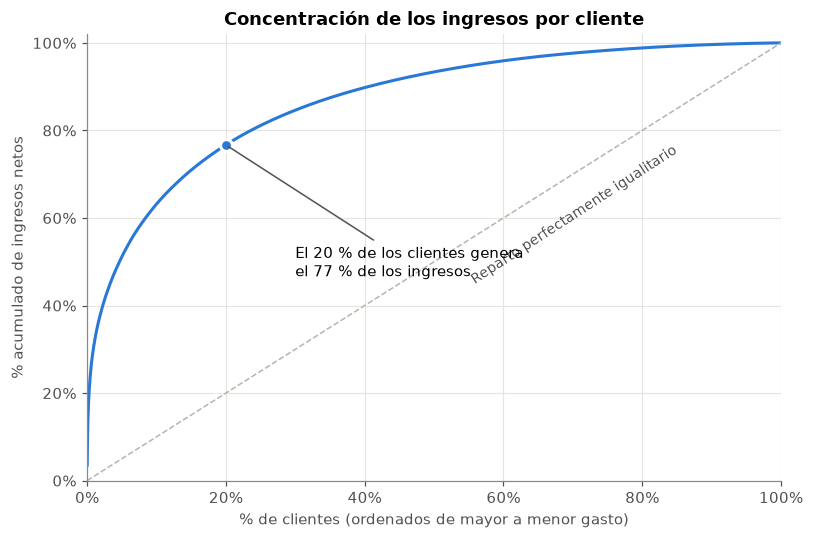

Top 1 % de clientes:  31.1 % de los ingresos
Top 20 % de clientes: 76.7 % de los ingresos


In [14]:
gasto_ordenado = features["gasto"].sort_values(ascending=False)
pct_clientes = np.arange(1, len(gasto_ordenado) + 1) / len(gasto_ordenado) * 100
pct_ingresos = gasto_ordenado.cumsum() / gasto_ordenado.sum() * 100

top1 = pct_ingresos.iloc[int(len(gasto_ordenado) * 0.01) - 1]
top20 = pct_ingresos.iloc[int(len(gasto_ordenado) * 0.20) - 1]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(pct_clientes, pct_ingresos, color=AZUL)
ax.plot([0, 100], [0, 100], color=GRIS, linestyle="--", linewidth=1)
ax.text(55, 45, "Reparto perfectamente igualitario", color="#52514e", fontsize=9, rotation=33)
ax.scatter([20], [top20], color=AZUL, s=60, zorder=3, edgecolor="white", linewidth=2)
ax.annotate(f"El 20 % de los clientes genera\nel {top20:.0f} % de los ingresos",
            xy=(20, top20), xytext=(30, top20 - 30), fontsize=10,
            arrowprops=dict(arrowstyle="-", color="#52514e"))
ax.set_xlabel("% de clientes (ordenados de mayor a menor gasto)")
ax.set_ylabel("% acumulado de ingresos netos")
ax.set_title("Concentración de los ingresos por cliente")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
plt.tight_layout()
plt.show()

print(f"Top 1 % de clientes:  {top1:.1f} % de los ingresos")
print(f"Top 20 % de clientes: {top20:.1f} % de los ingresos")

Se cumple (e incluso se supera) el **principio de Pareto**: una minoría de clientes concentra la mayor parte de los ingresos. Esto tiene una implicación directa para la empresa: **perder a uno de estos clientes cuesta mucho más que perder a un cliente medio**, por lo que las acciones de retención deben priorizarse según su valor (bloque D del esquema).

### 7. Distribución de las variables RFM
Los algoritmos de clustering basados en distancias (como K-Means) son muy sensibles a la forma de las distribuciones: si una variable tiene una cola muy larga, unos pocos clientes extremos dominan las distancias y el algoritmo acaba creando grupos "de un solo cliente". Comparamos la distribución original con la transformación logarítmica `log(1 + x)`.

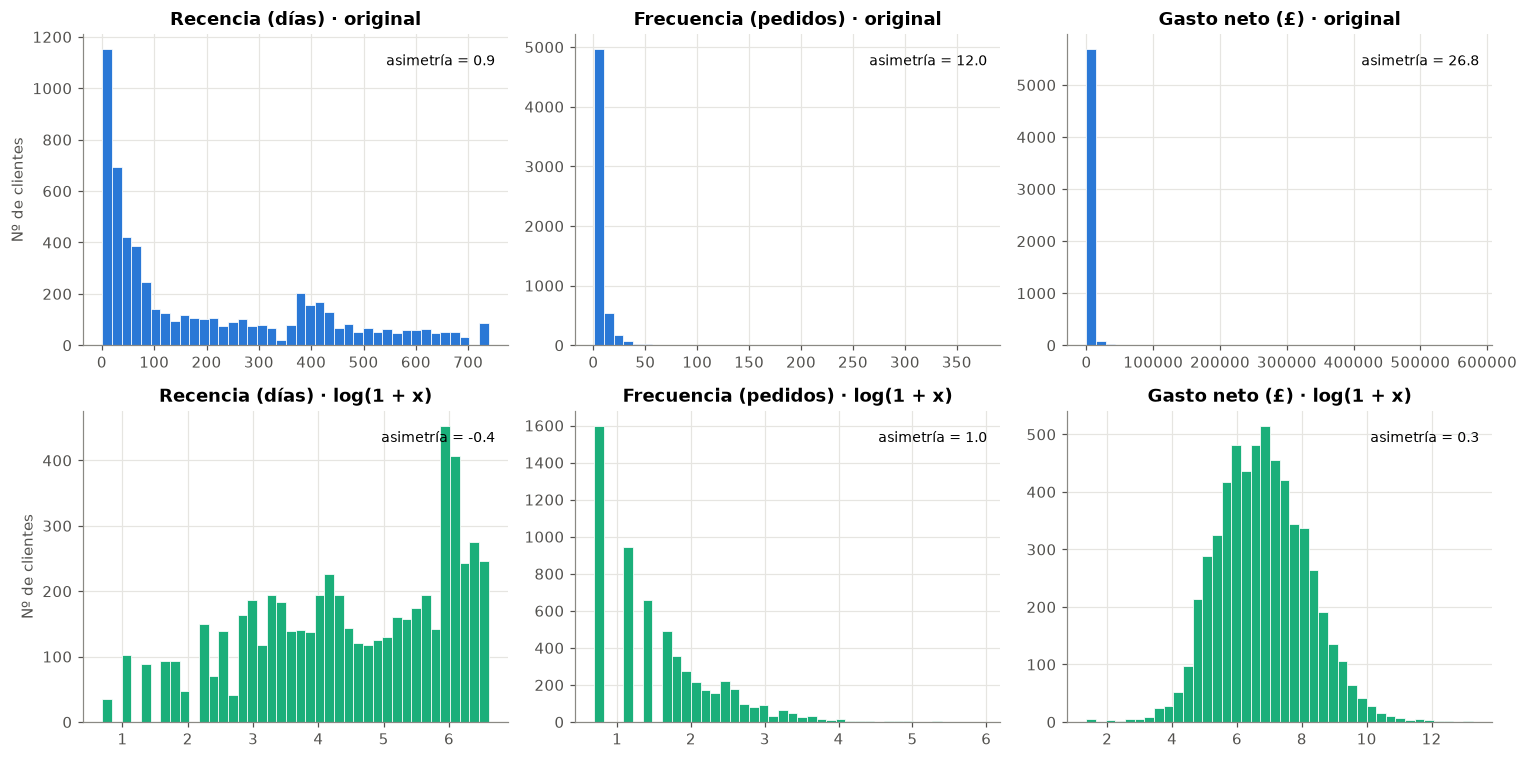

In [15]:
variables_rfm = ["recencia", "frecuencia", "gasto"]
etiquetas = {"recencia": "Recencia (días)", "frecuencia": "Frecuencia (pedidos)", "gasto": "Gasto neto (£)"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, variable in enumerate(variables_rfm):
    axes[0, col].hist(features[variable], bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
    axes[0, col].set_title(f"{etiquetas[variable]} · original")
    axes[1, col].hist(np.log1p(features[variable]), bins=40, color=AQUA, edgecolor="white", linewidth=0.5)
    axes[1, col].set_title(f"{etiquetas[variable]} · log(1 + x)")
    asimetria_orig = features[variable].skew()
    asimetria_log = np.log1p(features[variable]).skew()
    axes[0, col].text(0.97, 0.9, f"asimetría = {asimetria_orig:.1f}", transform=axes[0, col].transAxes, ha="right", fontsize=9)
    axes[1, col].text(0.97, 0.9, f"asimetría = {asimetria_log:.1f}", transform=axes[1, col].transAxes, ha="right", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Nº de clientes")
plt.tight_layout()
plt.show()

- **Frecuencia y gasto** tienen una asimetría enorme (la mayoría de clientes concentrados a la izquierda y unos pocos con valores altísimos). Con el logaritmo pasan a distribuciones mucho más simétricas.
- **Recencia** es menos extrema, pero también está muy cargada de clientes recientes con una larga cola de inactivos. El logaritmo la vuelve más equilibrada y tiene sentido de negocio: la diferencia entre 5 y 30 días sin comprar es mucho más relevante que entre 400 y 425.

Usaremos estas transformaciones en el clustering.

### 8. Valores extremos
¿Eliminamos los clientes con gastos extremos? Veamos quiénes son:

In [16]:
features.sort_values("gasto", ascending=False).head(8)[
    ["pais", "recencia", "frecuencia", "gasto", "ticket_medio", "unidades"]
].round(0)

,pais,recencia,frecuencia,gasto,ticket_medio,unidades
customer_id,,,,,,
18102,United Kingdom,1,145,578409.0,3989.0,181645
14646,Netherlands,2,145,523203.0,3608.0,367072
14156,EIRE,10,144,297775.0,2068.0,164281
14911,EIRE,2,373,258522.0,693.0,147804
17450,United Kingdom,9,51,233644.0,4581.0,83914
13694,United Kingdom,4,143,190392.0,1331.0,188201
17511,United Kingdom,3,60,168504.0,2808.0,117174
12415,Australia,25,24,143107.0,5963.0,91443


**No los eliminamos.** No son errores: son clientes reales (muchos parecen mayoristas, con cientos de pedidos y decenas de miles de unidades) y precisamente los más importantes para el negocio. Eliminarlos sería quitar a los mejores clientes del análisis. En su lugar, la **transformación logarítmica** reduce su influencia en el clustering sin perderlos.

### 9. Relaciones entre variables
Usamos la correlación de **Spearman** (basada en rangos) en lugar de Pearson porque nuestras variables están muy sesgadas y las relaciones no son lineales.

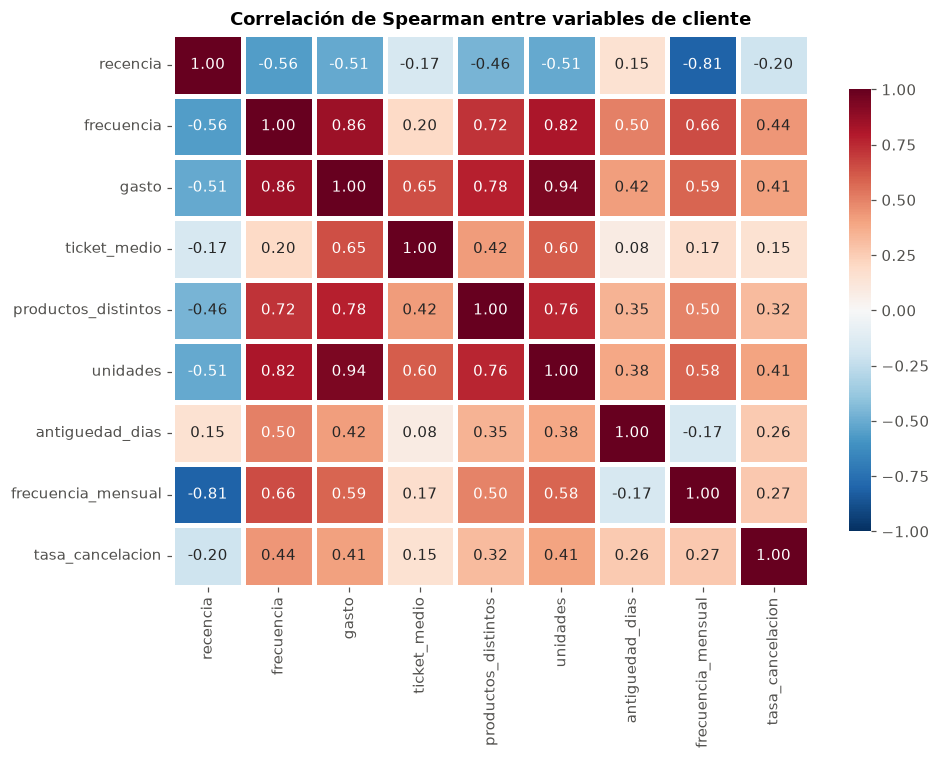

In [17]:
variables_numericas = ["recencia", "frecuencia", "gasto", "ticket_medio", "productos_distintos",
                       "unidades", "antiguedad_dias", "frecuencia_mensual", "tasa_cancelacion"]
correlaciones = features[variables_numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlación de Spearman entre variables de cliente")
ax.grid(False)
plt.tight_layout()
plt.show()

- **Frecuencia, gasto, productos distintos y unidades** están muy correlacionadas entre sí: los clientes que compran más veces compran más productos y gastan más. Si las metiéramos todas en el clustering, estaríamos **contando varias veces la misma información** ("volumen de compra") y dándole más peso del que merece.
- **Recencia** tiene correlación negativa con frecuencia y gasto: los mejores clientes suelen haber comprado recientemente.
- **Ticket medio** está relativamente poco relacionado con la frecuencia: hay clientes que compran poco pero en pedidos grandes, y viceversa.

- **Frecuencia mensual** está muy correlacionada (negativamente) con la recencia (-0,81): los clientes que han dejado de comprar acumulan meses sin pedidos, así que repite información de la recencia.

Incluso frecuencia y gasto están bastante relacionadas (0,86), pero miden conceptos de negocio distintos (hábito frente a valor) y juntas con la recencia forman el estándar **RFM**. Por eso empezaremos la segmentación con esas **tres variables**, muy interpretables, en lugar de añadir más variables de volumen que repetirían la misma información.

#### ¿Existen diferentes tipos de clientes?
Un primer vistazo a frecuencia frente a gasto (en escala logarítmica) coloreado por recencia:

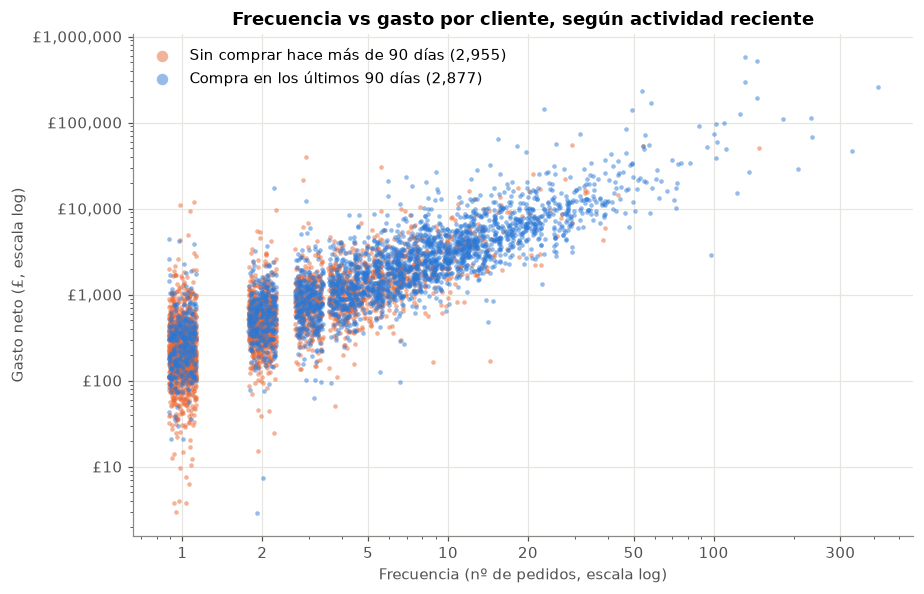

In [18]:
rng = np.random.default_rng(42)
# Pequeño "jitter" horizontal: la frecuencia es un número entero y sin él los puntos se apilarían en columnas
frecuencia_jitter = features["frecuencia"] * np.exp(rng.uniform(-0.12, 0.12, len(features)))
activo = features["recencia"] <= 90

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for mascara, color, etiqueta in [(~activo, NARANJA, "Sin comprar hace más de 90 días"),
                                 (activo, AZUL, "Compra en los últimos 90 días")]:
    ax.scatter(frecuencia_jitter[mascara], features.loc[mascara, "gasto"], s=9, alpha=0.5,
               color=color, linewidths=0, label=f"{etiqueta} ({mascara.sum():,})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 300])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax.set_xlabel("Frecuencia (nº de pedidos, escala log)")
ax.set_ylabel("Gasto neto (£, escala log)")
ax.set_title("Frecuencia vs gasto por cliente, según actividad reciente")
ax.legend(frameon=False, loc="upper left", markerscale=2.5)
plt.tight_layout()
plt.show()

Se intuyen perfiles distintos: abajo a la izquierda, clientes de **una o pocas compras**, muchos de ellos **inactivos** (naranja); arriba a la derecha, clientes **frecuentes, de alto gasto y casi siempre activos** (azul). No hay grupos totalmente separados, sino un continuo, por eso necesitamos un algoritmo de clustering que encuentre los cortes de forma objetiva. Es lo que haremos en el siguiente notebook.

### 10. Guardamos la tabla de features

In [19]:
features.to_csv(RUTA_FEATURES)
con.close()
print(f"Guardado {RUTA_FEATURES} con {features.shape[0]:,} clientes y {features.shape[1]} variables")

Guardado ..\data\processed\features_clientes.csv con 5,832 clientes y 15 variables


### 11. Conclusiones

- Hemos construido una tabla con **una fila por cliente** y 15 variables, a partir de la base de datos limpia y usando SQL (CTEs y funciones ventana).
- Usamos el **gasto neto** (compras − cancelaciones): con gasto bruto, clientes que cancelaron pedidos de más de 100.000 £ aparecerían como los mejores clientes.
- Los ingresos están **muy concentrados**: el 20 % de los clientes genera más de tres cuartas partes de los ingresos y el 1 % genera casi un tercio. No todos los clientes valen lo mismo.
- La mitad de las recompras se produce en aproximadamente un mes y el 90 % antes de unos 5 meses: es un buen umbral de referencia para detectar clientes en riesgo.
- Frecuencia y gasto son muy asimétricas → aplicaremos **logaritmos** en el clustering. Los valores extremos son clientes reales y valiosos, por lo que **no se eliminan**.
- Muchas variables de volumen son redundantes entre sí → empezaremos la segmentación con **RFM**.

**Siguiente paso →** `04_segmentacion_clientes`: aplicaremos K-Means sobre las variables RFM para descubrir los grupos de clientes, los interpretaremos y propondremos acciones de negocio para cada uno.